In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

processed_dir = project_root / "data" / "processed"
reports_dir = project_root / "reports"
reports_dir.mkdir(parents=True, exist_ok=True)

df_actual = pd.read_csv(
    processed_dir / "survey_actual.csv"
)

df_dummy = pd.read_csv(
    processed_dir / "survey_dummy.csv"
)

print("=== DATASET CUSTOMER SURVEY ===")
print("Respons actual:", len(df_actual))
print("Respons dummy:", len(df_dummy))
print("Total:", len(df_actual) + len(df_dummy))

=== DATASET CUSTOMER SURVEY ===
Respons actual: 2
Respons dummy: 98
Total: 100


In [3]:
print("=== VALIDASI DATA EDA ===")

assert df_actual["data_type"].eq("actual").all()
assert df_dummy["data_type"].eq("dummy").all()

assert set(df_actual["response_id"]).isdisjoint(
    set(df_dummy["response_id"])
)

print("Data actual dan dummy terpisah dengan benar.")

print("\nKolom dataset:")
print(df_actual.columns.tolist())

=== VALIDASI DATA EDA ===
Data actual dan dummy terpisah dengan benar.

Kolom dataset:
['response_id', 'submitted_at', 'respondent_type', 'information_needed', 'main_information', 'preferred_platform', 'information_difficulty', 'website_expectation', 'additional_feedback', 'consent', 'data_type', 'consent_bool']


In [4]:
print("=== RESPONS AKTUAL ===")

columns = [
    "response_id",
    "respondent_type",
    "information_needed",
    "main_information",
    "preferred_platform",
    "information_difficulty"
]

display(df_actual[columns])

=== RESPONS AKTUAL ===


,response_id,respondent_type,information_needed,main_information,preferred_platform,information_difficulty
0,R001,Pernah,"Jam Operasional, Lokasi, Fasilitas, Harga, Menu",Harga,Google Maps,2
1,R002,Pernah,"Promo/Event, Jam Operasional",Harga,Instagram,3


In [5]:
print("=== INFORMASI UTAMA RESPONDEN AKTUAL ===")

actual_information = (
    df_actual["main_information"]
    .value_counts()
    .rename_axis("informasi")
    .reset_index(name="jumlah_responden")
)

display(actual_information)

=== INFORMASI UTAMA RESPONDEN AKTUAL ===


,informasi,jumlah_responden
0,Harga,2


In [6]:
print("=== DEMONSTRASI INFORMASI UTAMA ===")

dummy_information = (
    df_dummy["main_information"]
    .value_counts()
    .rename_axis("informasi")
    .reset_index(name="jumlah")
)

dummy_information["persentase"] = (
    dummy_information["jumlah"]
    / len(df_dummy) * 100
).round(2)

display(dummy_information)

=== DEMONSTRASI INFORMASI UTAMA ===


,informasi,jumlah,persentase
0,Menu,30,30.61
1,Harga,21,21.43
2,Promo/Event,19,19.39
3,Lokasi,11,11.22
4,Jam Operasional,10,10.20
5,Fasilitas,7,7.14


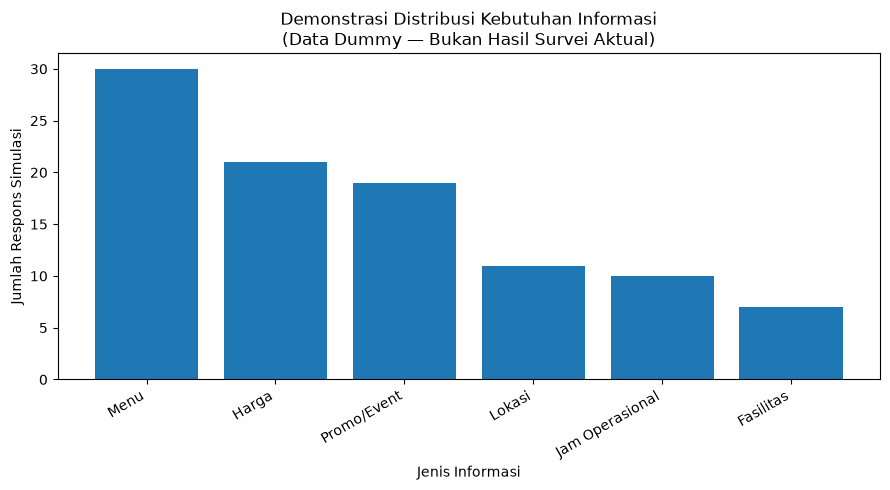

In [7]:
plt.figure(figsize=(9, 5))

plt.bar(
    dummy_information["informasi"],
    dummy_information["jumlah"]
)

plt.title(
    "Demonstrasi Distribusi Kebutuhan Informasi\n"
    "(Data Dummy — Bukan Hasil Survei Aktual)"
)

plt.xlabel("Jenis Informasi")
plt.ylabel("Jumlah Respons Simulasi")
plt.xticks(rotation=30, ha="right")

plt.tight_layout()
plt.show()

In [8]:
print("=== DEMONSTRASI PLATFORM PENCARIAN ===")

dummy_platform = (
    df_dummy["preferred_platform"]
    .value_counts()
    .rename_axis("platform")
    .reset_index(name="jumlah")
)

display(dummy_platform)

=== DEMONSTRASI PLATFORM PENCARIAN ===


,platform,jumlah
0,Instagram,31
1,Website Resmi,22
2,TikTok,20
3,Google Maps,16
4,Lainnya,9


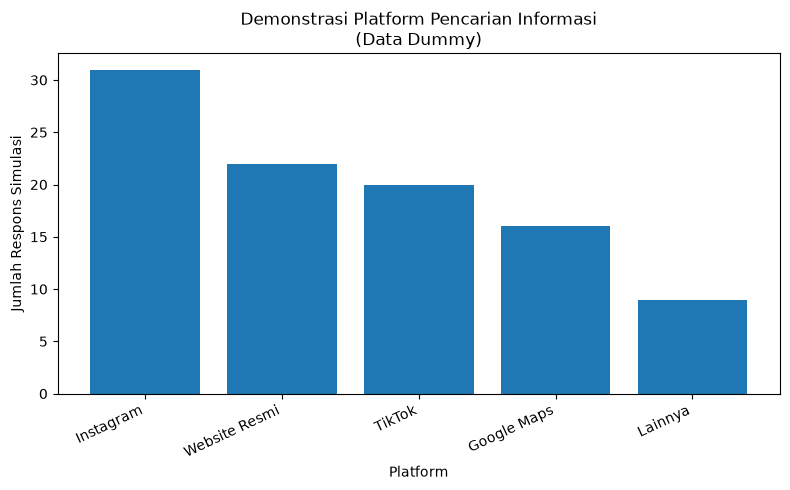

In [9]:
plt.figure(figsize=(8, 5))

plt.bar(
    dummy_platform["platform"],
    dummy_platform["jumlah"]
)

plt.title(
    "Demonstrasi Platform Pencarian Informasi\n"
    "(Data Dummy)"
)

plt.xlabel("Platform")
plt.ylabel("Jumlah Respons Simulasi")
plt.xticks(rotation=25, ha="right")

plt.tight_layout()
plt.show()

In [10]:
print("=== DEMONSTRASI SKALA KESULITAN ===")

difficulty_counts = (
    df_dummy["information_difficulty"]
    .value_counts()
    .sort_index()
    .rename_axis("skala")
    .reset_index(name="jumlah")
)

display(difficulty_counts)

=== DEMONSTRASI SKALA KESULITAN ===


,skala,jumlah
0,1,12
1,2,19
2,3,23
3,4,28
4,5,16


In [11]:
actual_information.to_csv(
    reports_dir / "survey_actual_information.csv",
    index=False,
    encoding="utf-8-sig"
)

dummy_information.to_csv(
    reports_dir / "survey_dummy_information.csv",
    index=False,
    encoding="utf-8-sig"
)

dummy_platform.to_csv(
    reports_dir / "survey_dummy_platform.csv",
    index=False,
    encoding="utf-8-sig"
)

difficulty_counts.to_csv(
    reports_dir / "survey_dummy_difficulty.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Hasil EDA survei berhasil disimpan.")

Hasil EDA survei berhasil disimpan.


In [12]:
print("=== VALIDASI KONSISTENSI JAWABAN AKTUAL ===")

def check_consistency(row):
    selected = [
        item.strip().lower()
        for item in str(row["information_needed"]).split(",")
    ]

    main = str(row["main_information"]).strip().lower()

    return main in selected

df_actual["main_info_consistent"] = df_actual.apply(
    check_consistency,
    axis=1
)

display(
    df_actual[
        [
            "response_id",
            "information_needed",
            "main_information",
            "main_info_consistent"
        ]
    ]
)

print(
    "Jumlah jawaban tidak konsisten:",
    (~df_actual["main_info_consistent"]).sum()
)

=== VALIDASI KONSISTENSI JAWABAN AKTUAL ===


,response_id,information_needed,main_information,main_info_consistent
0,R001,"Jam Operasional, Lokasi, Fasilitas, Harga, Menu",Harga,True
1,R002,"Promo/Event, Jam Operasional",Harga,False


Jumlah jawaban tidak konsisten: 1


In [13]:
from pathlib import Path

reports_dir = project_root / "reports"
reports_dir.mkdir(parents=True, exist_ok=True)

validation_result = df_actual[
    [
        "response_id",
        "information_needed",
        "main_information",
        "main_info_consistent"
    ]
].copy()

validation_result.to_csv(
    reports_dir / "survey_consistency_validation.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Hasil validasi berhasil disimpan.")
print(
    "Respons perlu ditinjau:",
    (~validation_result["main_info_consistent"]).sum()
)

Hasil validasi berhasil disimpan.
Respons perlu ditinjau: 1
